# 00b — Dataset report tables, validity checks and figures

Run AFTER notebook 00 (any time, also in a fresh session). It only READS `manifest.csv` and `data_v2.zip` from Drive: it never changes the dataset or the manifest md5.

It saves to `results/`: `dataset_class_split.csv`, `dataset_source_split.csv`, `dataset_class_weights.csv`, `dataset_source_image_stats.csv`, `dataset_summary.json`,
and the figures `dataset_train_balance.png`, `dataset_eval_sets.png`, `dataset_ood_sources.png`, `dataset_shortcut_check.png`.

It also adds the checks notebook 00 did not print: missing values in the manifest, blank / near-constant images, and per-source image statistics (to spot "shortcuts", e.g. one source being much darker or smaller than the others).

In [1]:
from google.colab import drive; drive.mount("/content/drive")
import json, zipfile, io, hashlib, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
D = Path("/content/drive/MyDrive/plant-disease-v2"); R = D / "results"; R.mkdir(exist_ok=True)
man = pd.read_csv(D / "manifest.csv"); meta = json.load(open(D / "meta.json")); CN = meta["class_names"]; SHORT = [c.replace("___", " | ")[:34] for c in CN]
md5 = hashlib.md5(open(D / "manifest.csv", "rb").read()).hexdigest(); zf = zipfile.ZipFile(D / "data_v2.zip")
assert hashlib.md5(zf.read("manifest.csv")).hexdigest() == md5, "manifest on Drive != manifest in zip: re-run notebook 00"
print("manifest md5:", md5, "|", len(man), "images")

ok, bad = [], []
def check(name, cond, detail=""): (ok if cond else bad).append(name); print(("PASS  " if cond else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))
print("== missing / invalid values in the manifest ==")
req = ["path", "label", "source", "split", "y"]
na = man[req].isna().sum(); check("no missing values in path/label/source/split/y", na.sum() == 0, str(na[na > 0].to_dict()) if na.sum() else "")
check("every label is a known class", man.label.isin(CN).all())
check("every split name is valid", set(man.split) <= {"train", "val", "test", "field_test", "scene_test", "ood_test"}, str(sorted(set(man.split))))
check("y is an integer in [0, 10] and matches the label", man.y.between(0, len(CN) - 1).all() and (man.y == man.label.map({c: i for i, c in enumerate(CN)})).all())
dp = man[man.path.duplicated(keep=False)].sort_values("path")
gp = dp.groupby("path").agg(ns=("split", "nunique"), nl=("label", "nunique")) if len(dp) else pd.DataFrame({"ns": [], "nl": []})
check("file paths shared by several rows (if any) stay in ONE split with ONE label, and are rare (< 0.1% of rows)", bool(((gp.ns == 1) & (gp.nl == 1)).all()) and man.path.duplicated().sum() < 0.001 * len(man),
      f"{man.path.duplicated().sum()} extra rows over {dp.path.nunique()} paths")
if len(dp): print("rows sharing a file (a harmless double count: same split, same label):"); display(dp[["path", "label", "source", "split", "orig"]])
check("every image of the training set has a non-empty class", (man[man.split == "train"].label.value_counts().reindex(CN).fillna(0) > 0).all())

Mounted at /content/drive
manifest md5: c0c74aae5361191f93208dcd44c3a7f4 | 23145 images
== missing / invalid values in the manifest ==
PASS  no missing values in path/label/source/split/y
PASS  every label is a known class
PASS  every split name is valid   [['field_test', 'ood_test', 'scene_test', 'test', 'train', 'val']]
PASS  y is an integer in [0, 10] and matches the label
PASS  file paths shared by several rows (if any) stay in ONE split with ONE label, and are rare (< 0.1% of rows)   [4 extra rows over 2 paths]
rows sharing a file (a harmless double count: same split, same label):


,path,label,source,split,orig
19038,pd_crop/Corn_(maize)___Northern_Leaf_Blight/tr...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_crop,train,train_stock-photo-northern-corn-leaf-blight-nc...
19041,pd_crop/Corn_(maize)___Northern_Leaf_Blight/tr...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_crop,train,train_stock-photo-northern-corn-leaf-blight-nc...
19043,pd_crop/Corn_(maize)___Northern_Leaf_Blight/tr...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_crop,train,train_stock-photo-northern-corn-leaf-blight-nc...
19040,pd_scene/Corn_(maize)___Northern_Leaf_Blight/t...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_scene,train,train_stock-photo-northern-corn-leaf-blight-nc...
19042,pd_scene/Corn_(maize)___Northern_Leaf_Blight/t...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_scene,train,train_stock-photo-northern-corn-leaf-blight-nc...
19044,pd_scene/Corn_(maize)___Northern_Leaf_Blight/t...,Corn_(maize)___Northern_Leaf_Blight,plantdoc_scene,train,train_stock-photo-northern-corn-leaf-blight-nc...


PASS  every image of the training set has a non-empty class


In [2]:
# ---- per-image statistics straight from the zip (about 2-4 minutes): size, brightness, contrast, file size
st = []
for p in man.path:
    raw = zf.read(p); im = Image.open(io.BytesIO(raw)); w, h = im.size
    a = np.asarray(im.convert("RGB").resize((32, 32)), dtype=np.float32)
    st.append((w, h, a.mean(), a.std(), len(raw) / 1024))
S = pd.DataFrame(st, columns=["w", "h", "brightness", "contrast", "kb"]); man2 = pd.concat([man.reset_index(drop=True), S], axis=1)
man2["short_side"] = man2[["w", "h"]].min(axis=1); man2["aspect"] = man2[["w", "h"]].max(axis=1) / man2[["w", "h"]].min(axis=1)
blank = man2[(man2.contrast < 3)]
check("no blank / near-constant images (pixel std < 3)", len(blank) == 0, f"{len(blank)} found")
check("extreme aspect ratios (> 8) are rare (< 0.1% of images)", (man2.aspect > 8).mean() < 0.001, f"{(man2.aspect > 8).sum()} images > 8, max {man2.aspect.max():.1f}")
print(f"info: {(man2.aspect > 6).sum()} images have aspect ratio > 6 (thin PlantDoc leaf boxes). Eval uses Resize(256)+CenterCrop(224), i.e. the central square - harmless.")
if (man2.aspect > 6).any(): display(man2[man2.aspect > 6][["path", "source", "split", "label", "w", "h"]].head(15))
check("no image smaller than 32 px", (man2.short_side >= 32).all(), f"min {man2.short_side.min()}")
if len(blank): display(blank[["path", "source", "split", "label", "contrast"]].head(20))
src_stats = man2.groupby("source")[["short_side", "aspect", "brightness", "contrast", "kb"]].agg(["mean", "std"]).round(1); src_stats["n"] = man2.groupby("source").size()
display(src_stats); src_stats.to_csv(R / "dataset_source_image_stats.csv")
print(f"\n{len(ok)} checks passed, {len(bad)} failed." + ("" if not bad else "  FIX FIRST: " + "; ".join(bad)))

PASS  no blank / near-constant images (pixel std < 3)   [0 found]
PASS  extreme aspect ratios (> 8) are rare (< 0.1% of images)   [0 images > 8, max 6.3]
info: 2 images have aspect ratio > 6 (thin PlantDoc leaf boxes). Eval uses Resize(256)+CenterCrop(224), i.e. the central square - harmless.


,path,source,split,label,w,h
13355,pd_crop/Corn_(maize)___Northern_Leaf_Blight/tr...,plantdoc_crop,train,Corn_(maize)___Northern_Leaf_Blight,482,77
13540,pd_crop/Corn_(maize)___Northern_Leaf_Blight/tr...,plantdoc_crop,val,Corn_(maize)___Northern_Leaf_Blight,836,132


PASS  no image smaller than 32 px   [min 55]


short_side       aspect       brightness             \
                                mean   std   mean  std        mean        std   
source                                                                          
caltech_unseen_objects         226.1  46.1    1.4  0.3  128.000000  50.299999   
faces_lfw                      250.0   0.0    1.0  0.0   99.300003  26.799999   
heldout_pv_apple_tomato        256.0   0.0    1.0  0.0  113.699997  15.600000   
neg_caltech                    229.8  41.9    1.4  0.3  139.800003  48.299999   
neg_flowers                    320.0   0.0    1.3  0.2   93.599998  26.200001   
neg_textures                   318.2   5.2    1.2  0.2  121.300003  41.500000   
pets_ood                       310.3  29.2    1.4  0.1  116.099998  31.900000   
plantdoc_crop                  236.3  89.0    1.6  0.7  110.800003  30.900000   
plantdoc_other_crops           226.1  89.2    1.5  0.5  120.199997  34.200001   
plantdoc_other_crops_TEST      248.9  89.5    1.6  0.5  127.400002  40.000000   
plantdoc_other_scene           317.5  14.1    1.4  0.3  125.000000  44.200001   
plantdoc_other_scene_TEST      305.0  43.6    1.3  0.2  138.199997  51.299999   
plantdoc_scene                 308.3  30.2    1.4  0.3  113.900002  32.000000   
plantvillage                   256.0   0.0    1.0  0.0  115.800003  19.900000   
pv_other_crops                 256.0   0.0    1.0  0.0  123.699997  18.000000   

                            contrast               kb            n  
                                mean        std  mean   std         
source                                                              
caltech_unseen_objects     58.700001  17.900000  20.3   8.1    468  
faces_lfw                  63.500000   9.800000  15.2   2.0    700  
heldout_pv_apple_tomato    39.599998   8.700000  24.0   7.1    840  
neg_caltech                59.299999  17.700001  19.9   8.1    660  
neg_flowers                61.200001  11.300000  37.5   9.9    600  
neg_textures               41.900002  18.799999  48.6  19.4    500  
pets_ood                   56.599998  13.100000  44.1  17.1    500  
plantdoc_crop              53.099998  12.600000  30.9  20.4   1478  
plantdoc_other_crops       57.400002  15.700000  26.3  17.3   3633  
plantdoc_other_crops_TEST  61.299999  16.900000  30.7  17.5    349  
plantdoc_other_scene       55.000000  13.200000  46.4  16.1    843  
plantdoc_other_scene_TEST  58.700001  14.000000  36.0  13.9    167  
plantdoc_scene             52.000000  12.100000  46.0  15.3    618  
plantvillage               47.299999  10.000000  23.7   5.4  10389  
pv_other_crops             43.099998   9.000000  24.5   5.8   1400


9 checks passed, 0 failed.


In [3]:
# ---- report tables
ct = pd.crosstab(man.label, man.split).reindex(CN); ct["total"] = ct.sum(axis=1); ct.to_csv(R / "dataset_class_split.csv")
cs = pd.crosstab(man.source, man.split); cs["total"] = cs.sum(axis=1); cs.to_csv(R / "dataset_source_split.csv")
tr = man[man.split == "train"].label.value_counts().reindex(CN); wts = len(man[man.split == "train"]) / (len(CN) * tr)
cw = pd.DataFrame({"train_images": tr, "loss_weight": wts.round(3), "share_of_train_%": (tr / tr.sum() * 100).round(1)}); cw.to_csv(R / "dataset_class_weights.csv")
display(ct); display(cs); display(cw)
inscope = CN[:-1]; imb_all = tr.max() / tr.min(); imb_in = tr[inscope].max() / tr[inscope].min()
print(f"class imbalance in train: {imb_all:.1f}x with the Other class, {imb_in:.1f}x among the 10 supported classes")
summary = dict(created=datetime.datetime.now().isoformat(timespec="seconds"), manifest_md5=md5, n_images=int(len(man)), class_names=CN,
               split_sizes={k: int(v) for k, v in man.split.value_counts().items()}, train_per_class={c: int(tr[c]) for c in CN},
               loss_weights={c: round(float(wts[c]), 3) for c in CN}, imbalance_with_other=round(float(imb_all), 2), imbalance_supported_only=round(float(imb_in), 2),
               images_per_source={k: int(v) for k, v in man.source.value_counts().items()}, blank_images=int(len(blank)),
               group_sim=meta.get("group_sim"), seed=meta.get("seed"), split_seed=meta.get("split_seed"),
               preprocessing="RGB JPEG q92, short side capped at 320 px; train aug on the fly (RandomResizedCrop, flips, rotation, color jitter, blur, erasing); eval Resize256+CenterCrop224+ImageNet norm",
               field_test_per_class={c: int(v) for c, v in man[man.split == "field_test"].label.value_counts().items()})
json.dump(summary, open(R / "dataset_summary.json", "w"), indent=2); print("saved dataset_summary.json")

split,field_test,ood_test,scene_test,test,train,val,total
label,,,,,,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,4,0,3,51,529,72,659
Corn_(maize)___Common_rust_,10,0,3,120,1155,140,1428
Corn_(maize)___Northern_Leaf_Blight,11,0,5,100,1259,156,1531
Corn_(maize)___healthy,0,0,0,115,932,115,1162
Grape___Black_rot,8,0,6,119,1094,143,1370
Grape___Esca_(Black_Measles),0,0,0,136,1109,138,1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot),0,0,0,107,862,107,1076
Grape___healthy,15,0,10,42,550,93,710
"Pepper,_bell___Bacterial_spot",15,0,8,101,1046,137,1307


split,field_test,ood_test,scene_test,test,train,val,total
source,,,,,,,
caltech_unseen_objects,0,468,0,0,0,0,468
faces_lfw,0,0,0,70,549,81,700
heldout_pv_apple_tomato,0,840,0,0,0,0,840
neg_caltech,0,0,0,52,544,64,660
neg_flowers,0,0,0,56,478,66,600
neg_textures,0,0,0,52,408,40,500
pets_ood,0,500,0,0,0,0,500
plantdoc_crop,74,0,0,0,1244,160,1478
plantdoc_other_crops,0,0,0,0,3312,321,3633


,train_images,loss_weight,share_of_train_%
label,,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,529,2.965,3.1
Corn_(maize)___Common_rust_,1155,1.358,6.7
Corn_(maize)___Northern_Leaf_Blight,1259,1.246,7.3
Corn_(maize)___healthy,932,1.683,5.4
Grape___Black_rot,1094,1.434,6.3
Grape___Esca_(Black_Measles),1109,1.414,6.4
Grape___Leaf_blight_(Isariopsis_Leaf_Spot),862,1.820,5.0
Grape___healthy,550,2.852,3.2
"Pepper,_bell___Bacterial_spot",1046,1.499,6.1


class imbalance in train: 13.6x with the Other class, 2.9x among the 10 supported classes
saved dataset_summary.json


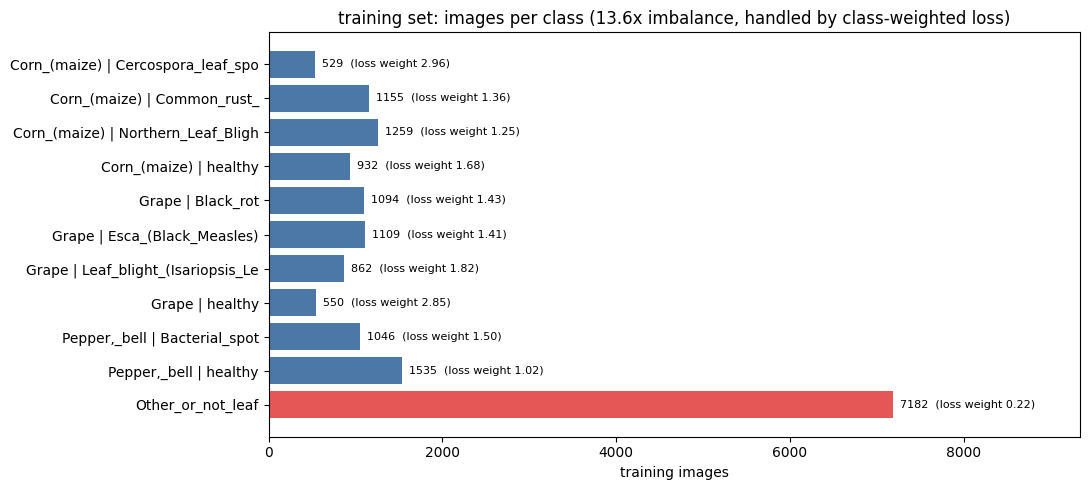

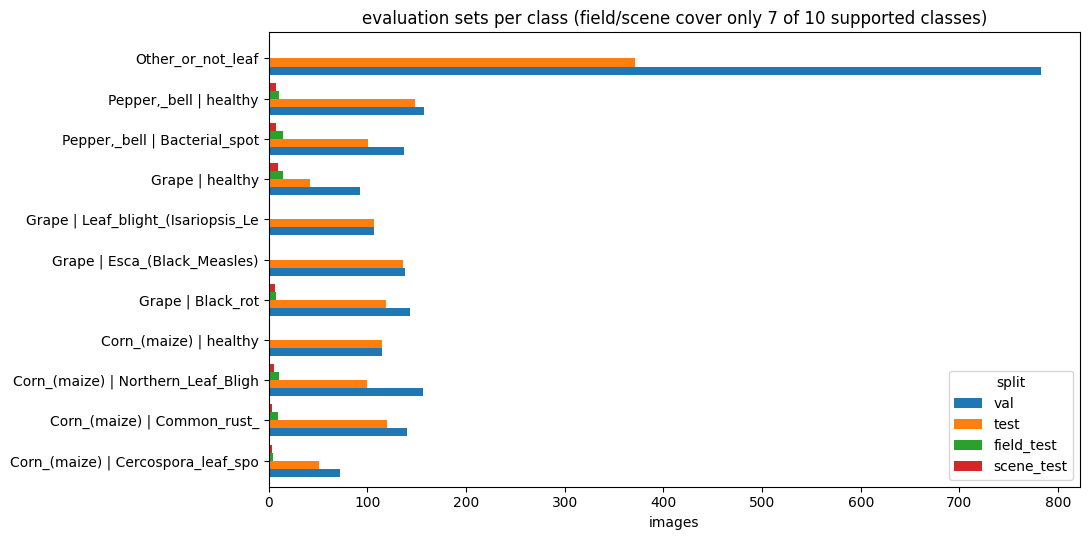

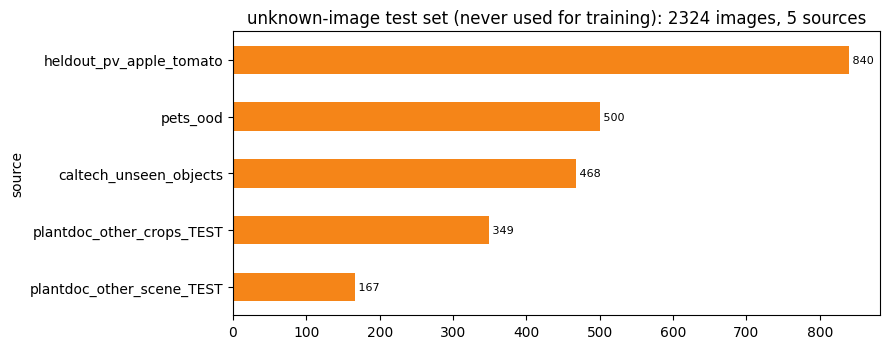

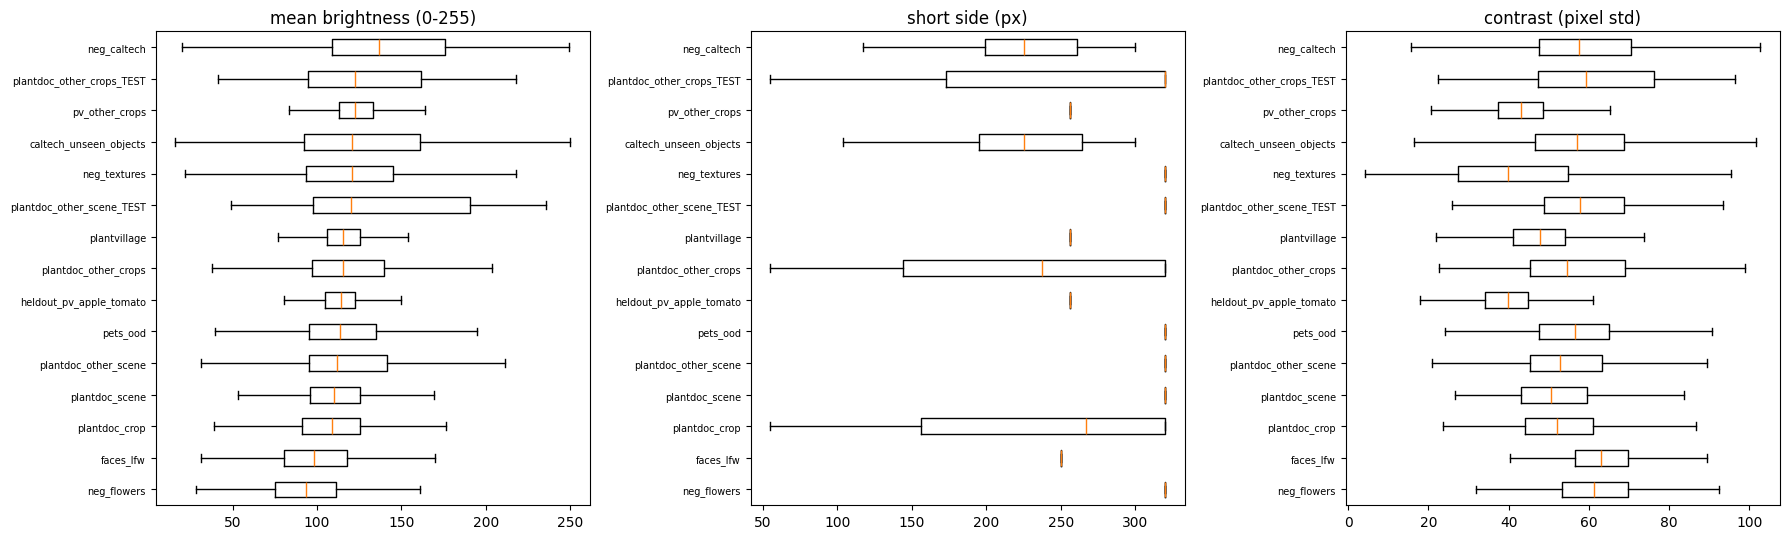

saved to /content/drive/MyDrive/plant-disease-v2/results : ['dataset_class_split.csv', 'dataset_class_split.png', 'dataset_class_weights.csv', 'dataset_eval_sets.png', 'dataset_image_sizes.png', 'dataset_ood_sources.png', 'dataset_samples_field_test.png', 'dataset_samples_ood_test.png', 'dataset_samples_per_class.png', 'dataset_shortcut_check.png', 'dataset_source_image_stats.csv', 'dataset_source_split.csv', 'dataset_source_split.png', 'dataset_summary.json', 'dataset_train_balance.png']


In [4]:
# ---- figures for the report
# 1) training-set class balance + the loss weight each class gets
fig, ax = plt.subplots(figsize=(11, 5)); colors = ["#4c78a8"] * 10 + ["#e45756"]
ax.barh(SHORT[::-1], tr.values[::-1], color=colors[::-1]); ax.set_xlabel("training images")
for i, (n, w) in enumerate(zip(tr.values[::-1], wts.values[::-1])): ax.text(n, i, f"  {n}  (loss weight {w:.2f})", va="center", fontsize=8)
ax.set_xlim(0, tr.max() * 1.3); ax.set_title(f"training set: images per class ({imb_all:.1f}x imbalance, handled by class-weighted loss)")
plt.tight_layout(); plt.savefig(R / "dataset_train_balance.png", dpi=140); plt.show()

# 2) the evaluation sets (without the unknown-image set)
ev = pd.crosstab(man.label, man.split).reindex(CN)[["val", "test", "field_test", "scene_test"]]
ev.index = SHORT; ax = ev.plot.barh(figsize=(11, 5.5), width=.8); ax.set_title("evaluation sets per class (field/scene cover only 7 of 10 supported classes)"); ax.set_xlabel("images")
plt.tight_layout(); plt.savefig(R / "dataset_eval_sets.png", dpi=140); plt.show()

# 3) unknown-image test set per source
oo = man[man.split == "ood_test"].source.value_counts()
fig, ax = plt.subplots(figsize=(9, 3.6)); oo.sort_values().plot.barh(ax=ax, color="#f58518")
for i, v in enumerate(oo.sort_values()): ax.text(v, i, f" {v}", va="center", fontsize=8)
ax.set_title(f"unknown-image test set (never used for training): {oo.sum()} images, {len(oo)} sources"); plt.tight_layout(); plt.savefig(R / "dataset_ood_sources.png", dpi=140); plt.show()

# 4) shortcut check: do sources differ a lot in brightness / size? (the network must not learn "dark = unknown")
order = list(man2.groupby("source").brightness.median().sort_values().index)
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, col, t in zip(ax, ["brightness", "short_side", "contrast"], ["mean brightness (0-255)", "short side (px)", "contrast (pixel std)"]):
    a.boxplot([man2[man2.source == s][col] for s in order], vert=False, showfliers=False); a.set_yticks(range(1, len(order) + 1)); a.set_yticklabels(order); a.set_title(t); a.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(R / "dataset_shortcut_check.png", dpi=140); plt.show()
print("saved to", R, ":", sorted(p.name for p in R.glob("dataset_*")))